# PFN quality: `pfn_large` vs the smoke PFN

## Description

**Question.** How good is `pfn_large`'s posterior predictive distribution (PPD) on held-out draws of
its training prior, per input dimension d and context size n, compared with the smoke PFN, and what does
a forward pass cost? This is also the port's **sanity check**: the evaluation was run before in
pfn-acqpolicy (`eval_pfn_large`, commit 58b6e2b), on the same draws.

**Setup.** Two registered checkpoints (`pfn_large`: 6.6M params, 1000 bins, trained on n ≤ 100;
`pfn_smoke`: 139k params, 64 bins, n ≤ 20) on 256 held-out BNN-prior functions per d = 1…6 (data seed
555,000 + d), 200 test points each, nested context prefixes n ∈ {1, …, 100}. Metrics per test point
(NLL incl. log bin width, squared error of the mean, CRPS, PIT, 50/90% coverage, predictive std) and
per function (Spearman of mean vs y, regret of picking the argmin of the mean); 95% bootstrap CIs over
functions. CPU forward cost (8 threads). 1-d panels: the PPD density on the bar intervals, mean, 5–95%
band, true function and context, for the three draws with the most local minima.

**What to look for.** Lower NLL/CRPS for `pfn_large` at every d and n; 90% coverage ≈ 0.9 (calibration);
monotone improvement in n; the smoke model's degradation beyond n = 20 (outside its training range);
in 1-d: the band collapsing onto the data near context points and widening away from them, the mean
tracking local minima once points are near them. Failure modes to spot at a glance: a band that does
not contain the true function, multimodal density far from data that ignores the context, a mean that
interpolates flat lines between points.

**Reproduced / not reproduced.** Reproduced if every metric in `metrics` matches the original run to
within 1e-5 (same draws, same code apart from import paths, CPU); otherwise the port changed behaviour
and the difference is explained before anything else is built on it. Timing is machine-dependent and
not part of the check.

**Limits.** In-distribution only (the BNN training prior, d ≤ 6, n ≤ 100); says nothing about real
benchmarks or about BO performance.

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pfn_repro.analysis import load_snapshot, show_header
from pfn_repro.evaluation.plots import ppd_heatmap
from pfn_repro.utils.env import repo_root

SNAPSHOT = "results/eval_pfn_large/sanity_20261021-135936"
CROSS = "results/eval_pfn_large/sanity_20261021-135934"  # the same commit on ulysses
REFERENCE = repo_root() / "results/eval_pfn_large/reference_pfn-acqpolicy"   # the original run, see its README
snap = load_snapshot(SNAPSHOT)
show_header(snap)
M, PF, PIT, TIME, H = (snap.table(t) for t in ("metrics", "per_function", "pit_hist", "timing", "history"))
DIMS = sorted(M.d.unique()); NS = sorted(M.n.unique())
plt.rcParams.update({"figure.dpi": 85, "axes.spines.top": False, "axes.spines.right": False})

## How it was run

```bash
just sweep detached sanity experiment=eval_pfn_large
```

|  |  |
|---|---|
| stage | sanity |
| sweep | `sanity_20261021-135936` |
| commit | `52bf85a8836f` (tag `sweep/eval_pfn_large/sanity_20261021-135936`) |
| backend / host | detached / ruhkopf-XPS-15-9510 |
| ran | 2026-10-21T13:59:37 → 2026-10-21T14:06:12 |
| members | 1: 1 done |
| compute | 6.5 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/eval_pfn_large.yaml`):

```yaml
# @package _global_
# pfn_large against the smoke checkpoint on the same held-out draws (the original eval_pfn_large).
defaults:
  - /prior: bnn
  - override /task: eval_pfn
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
prior:
  bias_std: 0.1
  depth_range: '[8, 32]'
  frac_relevant_features: 0.7
  log_amp_range: '[8.0, 20.0]'
  name: bnn
  output_noise_std_range: '[0.0004, 0.0013]'
  preactivation_noise_std_range: '[0.0003, 0.0014]'
  sparseness: 0.145
  width_range: '[32, 128]'
seed: 0
task:
  chunk: 32
  context_sizes: '[1, 2, 3, 5, 10, 20, 30, 50, 75, 100]'
  data_seed: 555000
  dims: '[1, 2, 3, 4, 5, 6]'
  models: '["pfn_large", "pfn_smoke"]'
  n_boot: 1000
  n_functions: 256
  n_test: 200
  name: eval_pfn
  slice.contexts: '[3, 8, 20, 50]'
  slice.density_x: 120
  slice.max_bins: 200
  slice.n_candidates: 256
  slice.n_functions: 3
  slice.n_grid: 400
  slice.seed: 4242
  threads: 8
  timing.batch: 16
  timing.n_test: 200
  timing.reps: 7
  val_every.pfn_large: 5000
```

## 0. Reproduction check

The same held-out draws were evaluated in pfn-acqpolicy (`REFERENCE`, on this laptop). Pre-registered
criterion: every summary metric within 1e-5 of the original. This snapshot is the run on the same laptop
(CPU, torch 2.14.1+cpu); `CROSS` is the same commit run on ulysses (another CPU, the cu126 torch build).

In [ ]:
old = pd.read_parquet(REFERENCE / "metrics.parquet").replace({"model": {"smoke": "pfn_smoke"}})
m = M.merge(old, on=["model", "d", "n", "metric"], suffixes=("", "_orig"))
m["abs_diff"] = (m["mean"] - m["mean_orig"]).abs()
print(f"{len(m)} of {len(M)} summary rows matched; max |diff| of the means = {m.abs_diff.max():.2e}; "
      f"within 1e-5: {bool((m.abs_diff <= 1e-5).all())}")
opf = pd.read_parquet(REFERENCE / "per_function.parquet").replace({"model": {"smoke": "pfn_smoke"}})
pm = PF.merge(opf, on=["model", "d", "n", "function"], suffixes=("", "_orig"))
cols = ["nll", "sq_err", "crps", "std", "cov90", "spearman", "select_regret"]
cross = load_snapshot(CROSS).table("per_function")
xm = PF.merge(cross, on=["model", "d", "n", "function"], suffixes=("", "_x"))
pd.DataFrame({c: {"same machine: max |diff|": (pm[c] - pm[c + "_orig"]).abs().max(),
                  "ulysses: max |diff|": (xm[c] - xm[c + "_x"]).abs().max(),
                  "ulysses: share of functions > 1e-5": ((xm[c] - xm[c + "_x"]).abs() > 1e-5).mean()} for c in cols}).T

960 of 960 summary rows matched; max |diff| of the means = 0.00e+00; within 1e-5: True


,same machine: max |diff|,ulysses: max |diff|,ulysses: share of functions > 1e-5
nll,0.0,0.012853,0.045638
sq_err,0.0,0.000005,0.000000
crps,0.0,0.000006,0.000000
std,0.0,0.000004,0.000000
cov90,0.0,0.005000,0.000326
spearman,0.0,0.000303,0.029525
select_regret,0.0,0.007122,0.000618


## 1. Training: architecture and learning curves

Read from the checkpoints (registry + the metadata stored in each file), not from configs.

In [ ]:
ck = snap.table("checkpoints")
pd.DataFrame([{"model": r.model, "params": f"{r.n_params:,}", "trained on n": f"{r.train_n_min}–{r.train_n_max}",
               "architecture": json.loads(r.metadata).get("config"), "source": json.loads(r.source)} for r in ck.itertuples()]).style.hide(axis="index")

model,params,trained on n,architecture,source
pfn_large,"6,579,688",1–100,"{'max_x_dim': 6, 'd_model': 256, 'n_heads': 8, 'n_layers': 8, 'd_ff': 1024, 'n_bins': 1000}","{'repo': 'pfn-acqpolicy', 'git_commit': '0b5683e8220e4947152544e45cf3cdc508ae3732', 'mlflow_run_id': '9ce11fd39e0b47df86c0efe694dba306', 'step': 1499999, 'experiment': 'pfn_large', 'trained_on': 'ulysses, 1x RTX 3090, ~24.5 h'}"
pfn_smoke,"139,200",3–20,"{'max_x_dim': 6, 'd_model': 64, 'n_heads': 4, 'n_layers': 4, 'd_ff': 128, 'n_bins': 64}","{'repo': 'AnytimeAcquisition', 'git_commit': 'd48bf610cc8ab58e2dbecda24bd7b0ad226510af', 'mlflow_run_id': 'd4615a19b6db4463b392ad80d75160ab', 'step': 29999}"


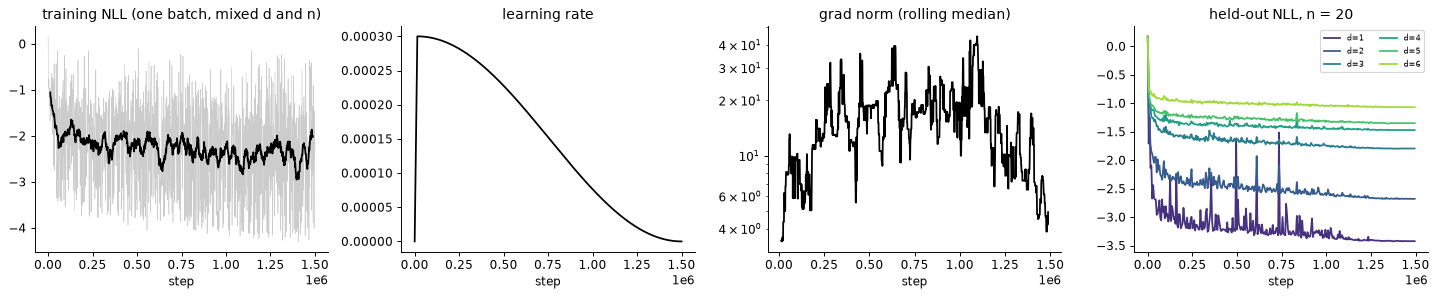

In [ ]:
h = H[H.model == "pfn_large"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].plot(h.step, h["nll/train"], color="#cccccc", lw=0.5); ax[0].plot(h.step, h["nll/train"].rolling(25, center=True).mean(), "k", lw=1.5)
ax[0].set_title("training NLL (one batch, mixed d and n)")
ax[1].plot(h.step, h["lr"], "k"); ax[1].set_title("learning rate")
ax[2].plot(h.step, h["grad_norm"].rolling(25, center=True).median(), "k"); ax[2].set_yscale("log"); ax[2].set_title("grad norm (rolling median)")
v = h.dropna(subset=["nll/val_d1_n20"])
for d in DIMS:
    ax[3].plot(v.step, v[f"nll/val_d{d}_n20"], color=plt.cm.viridis(d / 7), label=f"d={d}")
ax[3].set_title("held-out NLL, n = 20"); ax[3].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel("step")
fig.tight_layout(); plt.show()

## 2. NLL per d and context size

Density NLL includes the log bin width, so it is comparable across bin counts (64 vs 1000). Δ vs smoke is
paired over the same functions (positive = `pfn_large` better).

In [ ]:
def cell(model, d, n, metric="nll"):
    r = M[(M.model == model) & (M.d == d) & (M.n == n) & (M.metric == metric)].iloc[0]
    return f"{r['mean']:.3f} [{r.lo:.3f}, {r.hi:.3f}]"
rows = []
for d in DIMS:
    a = PF[(PF.model == "pfn_smoke") & (PF.d == d) & (PF.n == 20)].nll.to_numpy()
    b = PF[(PF.model == "pfn_large") & (PF.d == d) & (PF.n == 20)].nll.to_numpy()
    rows.append({"d": d, **{f"NLL n={n}": cell("pfn_large", d, n) for n in (5, 20, 50, 100)},
                 "smoke NLL n=20": cell("pfn_smoke", d, 20), "Δ vs smoke, n=20": f"{(a - b).mean():+.3f}"})
pd.DataFrame(rows).style.hide(axis="index")

d,NLL n=5,NLL n=20,NLL n=50,NLL n=100,smoke NLL n=20,"Δ vs smoke, n=20"
1,"-1.951 [-2.069, -1.831]","-3.509 [-3.618, -3.404]","-4.049 [-4.141, -3.953]","-4.222 [-4.299, -4.142]","-2.661 [-2.750, -2.569]",+0.849
2,"-1.411 [-1.536, -1.296]","-2.752 [-2.912, -2.601]","-3.420 [-3.556, -3.277]","-3.743 [-3.859, -3.630]","-1.672 [-1.767, -1.575]",+1.080
3,"-0.936 [-1.031, -0.839]","-2.036 [-2.187, -1.895]","-2.707 [-2.849, -2.563]","-3.123 [-3.267, -2.980]","-1.197 [-1.281, -1.108]",+0.840
4,"-0.768 [-0.870, -0.678]","-1.651 [-1.787, -1.511]","-2.257 [-2.426, -2.100]","-2.622 [-2.778, -2.459]","-1.060 [-1.147, -0.978]",+0.591
5,"-0.661 [-0.744, -0.576]","-1.399 [-1.530, -1.268]","-1.960 [-2.111, -1.810]","-2.324 [-2.481, -2.158]","-0.936 [-1.024, -0.855]",+0.463
6,"-0.548 [-0.608, -0.489]","-1.065 [-1.152, -0.971]","-1.536 [-1.652, -1.418]","-1.928 [-2.065, -1.789]","-0.782 [-0.850, -0.718]",+0.283


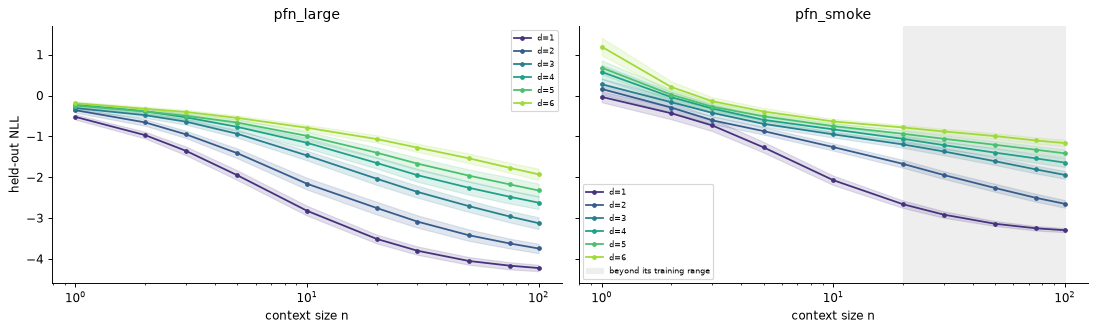

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, model in zip(ax, ("pfn_large", "pfn_smoke")):
    for d in DIMS:
        g = M[(M.model == model) & (M.d == d) & (M.metric == "nll")].sort_values("n")
        a.plot(g.n, g["mean"], "o-", ms=3, color=plt.cm.viridis(d / 7), label=f"d={d}")
        a.fill_between(g.n, g.lo, g.hi, color=plt.cm.viridis(d / 7), alpha=0.15)
    a.set_xscale("log"); a.set_title(model); a.set_xlabel("context size n")
ax[1].axvspan(20, 100, color="#eeeeee", zorder=-1, label="beyond its training range")
ax[0].set_ylabel("held-out NLL"); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); fig.tight_layout(); plt.show()

## 3. Beyond NLL: accuracy, calibration, ranking, decisions

MSE of the mean, CRPS (a proper score in y units), 90% central-interval coverage (calibrated = 0.9),
Spearman of the mean against y over a function's test points, and the regret of picking the test point
with the lowest mean. PIT histograms: flat = calibrated, U = overconfident, hump = underconfident.

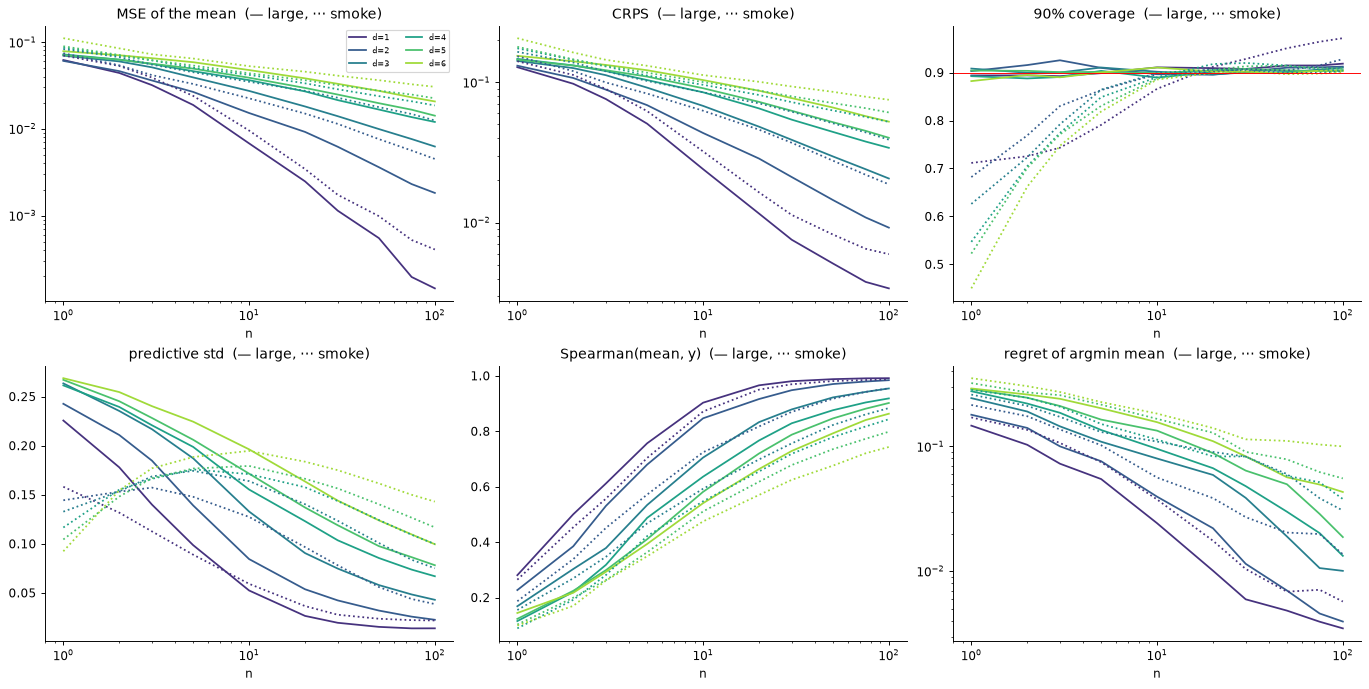

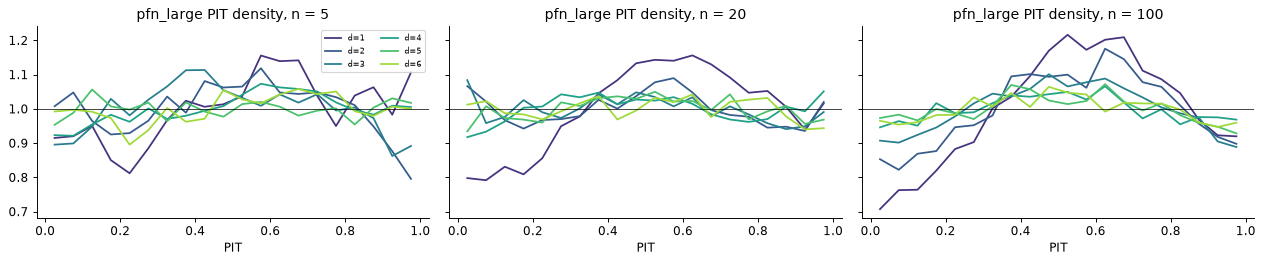

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for a, (metric, title, log) in zip(ax.ravel(), [("sq_err", "MSE of the mean", True), ("crps", "CRPS", True),
        ("cov90", "90% coverage", False), ("std", "predictive std", False), ("spearman", "Spearman(mean, y)", False),
        ("select_regret", "regret of argmin mean", True)]):
    for model, ls in (("pfn_large", "-"), ("pfn_smoke", ":")):
        for d in DIMS:
            g = M[(M.model == model) & (M.d == d) & (M.metric == metric)].sort_values("n")
            a.plot(g.n, g["mean"], ls, color=plt.cm.viridis(d / 7), label=f"d={d}" if model == "pfn_large" else None)
    if metric == "cov90": a.axhline(0.9, color="r", lw=0.8)
    a.set_xscale("log"); a.set_title(title + "  (— large, ⋯ smoke)"); a.set_xlabel("n")
    if log: a.set_yscale("log")
ax[0, 0].legend(fontsize=7, ncol=2); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for a, n in zip(ax, (5, 20, 100)):
    for d in DIMS:
        g = PIT[(PIT.model == "pfn_large") & (PIT.d == d) & (PIT.n == n)]
        a.plot((g.bin + 0.5) / 20, g.freq * 20, color=plt.cm.viridis(d / 7), label=f"d={d}")
    a.axhline(1, color="k", lw=0.6); a.set_title(f"pfn_large PIT density, n = {n}"); a.set_xlabel("PIT")
ax[0].legend(fontsize=7, ncol=2); fig.tight_layout(); plt.show()

## 4. Forward cost

Median CPU wall time of one forward pass (8 threads; 16 functions × 200 test points), averaged over d.
Machine-dependent: this is the evaluating machine (see the header).

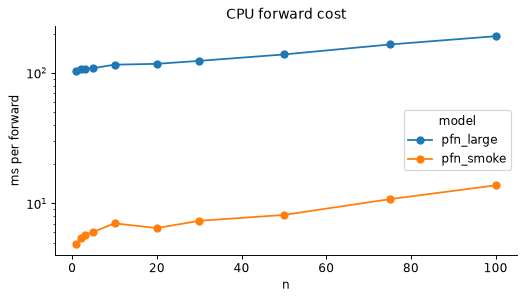

n,1,2,3,5,10,20,30,50,75,100
model,,,,,,,,,,
pfn_large,103.7,107.3,108.5,109.5,116.5,118.2,124.6,139.6,166.5,192.7
pfn_smoke,4.8,5.4,5.7,6.1,7.0,6.5,7.4,8.2,10.8,13.8


In [ ]:
t = TIME.groupby(["model", "n"]).ms.mean().unstack(0)
ax = t.plot(marker="o", figsize=(7, 3.5), logy=True); ax.set_ylabel("ms per forward"); ax.set_title("CPU forward cost"); plt.show()
t.round(1).T

## 5. 1-d panels: the PPD on its bar intervals

Three 1-d draws (those with the most local minima among 256 that span more than half of [0, 1]),
nested random contexts (noisy observations). Shading: the predictive density on the bar distribution's
intervals (1000 bins merged to at most 200, exact mass; the colour scale is capped at the 99th
percentile); lines: true f, mean, 5–95% band; dots: context. Top three rows `pfn_large`, bottom row
`pfn_smoke` on the first function for comparison. **Use as a reference** for future surrogates: the same
draws and contexts, so failure modes can be compared panel by panel.

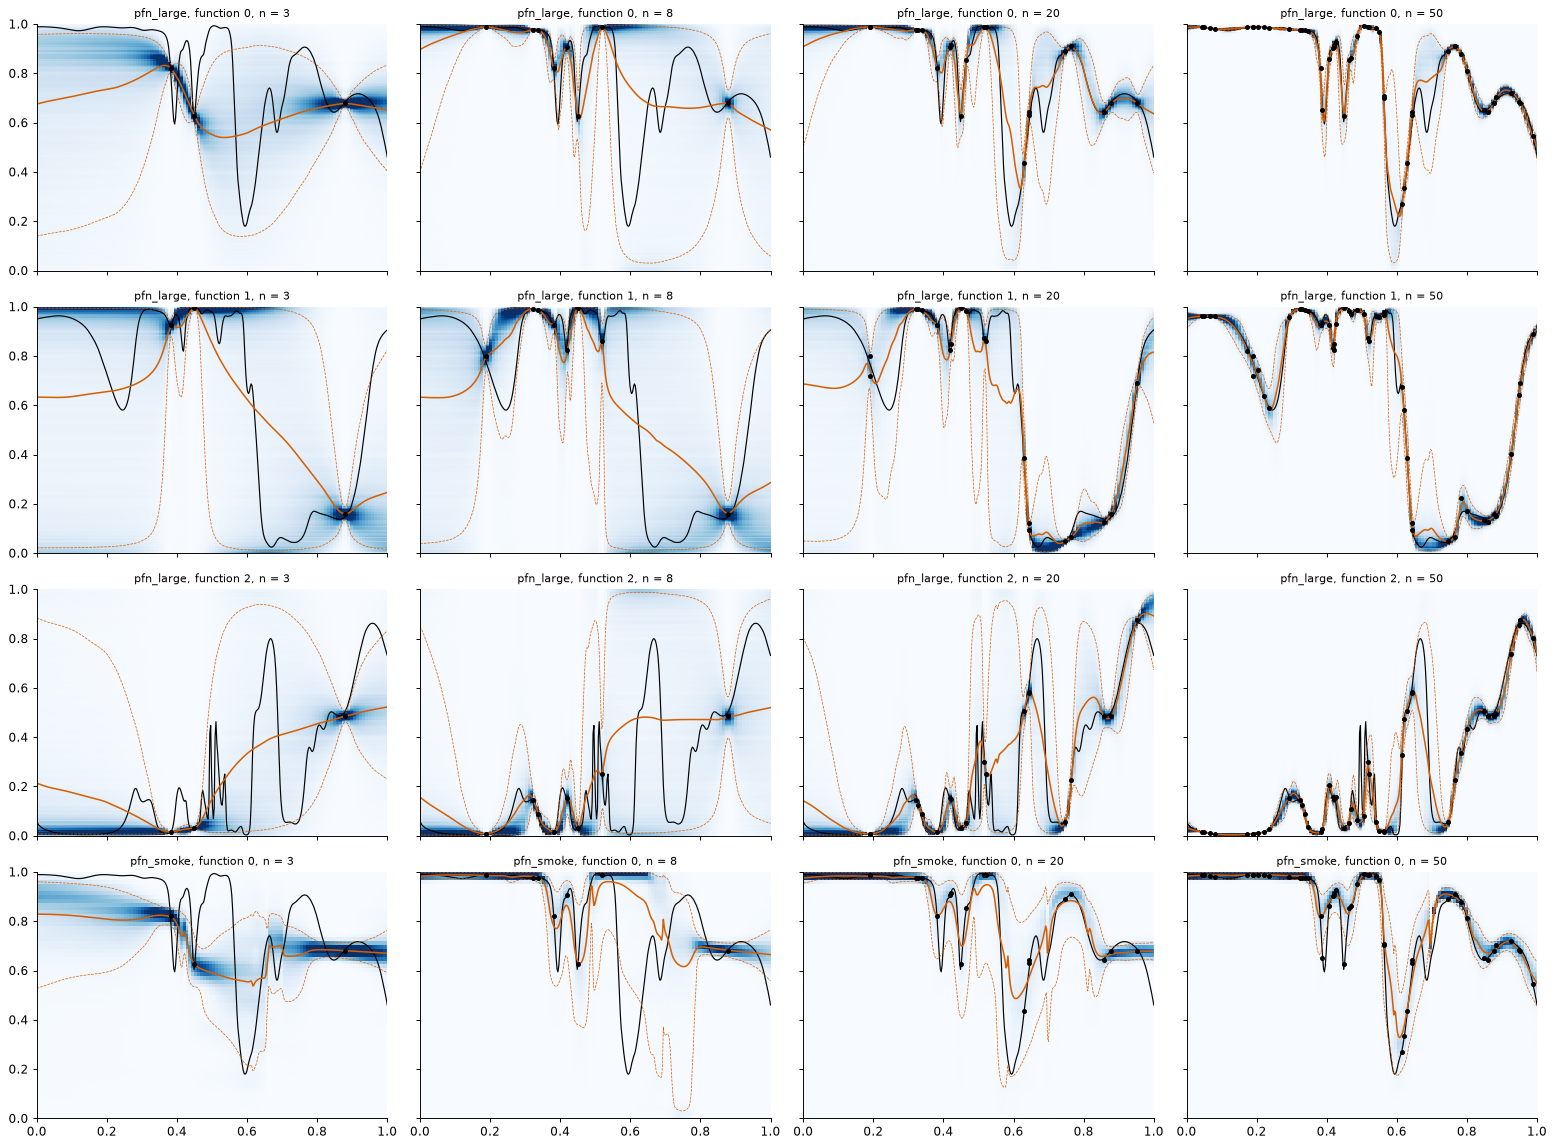

In [ ]:
L, C, D, B = (snap.table(t) for t in ("slice_lines", "slice_context", "slice_density", "slice_borders"))
ns = sorted(L.n.unique())
rows = [("pfn_large", f) for f in sorted(L.function.unique())] + [("pfn_smoke", 0)]
fig, axes = plt.subplots(len(rows), len(ns), figsize=(4.6 * len(ns), 3.4 * len(rows)), sharex=True, sharey=True)
for r, (model, fn) in enumerate(rows):
    for c, n in enumerate(ns):
        ax = axes[r, c]
        ppd_heatmap(ax, D[(D.model == model) & (D.function == fn) & (D.n == n)], B[B.model == model])
        l = L[(L.model == model) & (L.function == fn) & (L.n == n)]
        ctx = C[C.function == fn].sort_values("order").head(n)
        ax.plot(l.x, l.f_true, "k", lw=1); ax.plot(l.x, l["mean"], color="#D55E00", lw=1.3)
        ax.plot(l.x, l.q05, color="#D55E00", lw=0.6, ls="--"); ax.plot(l.x, l.q95, color="#D55E00", lw=0.6, ls="--")
        ax.scatter(ctx.x, ctx.y, color="k", s=10, zorder=5); ax.set_ylim(0, 1)
        ax.set_title(f"{model}, function {fn}, n = {n}", fontsize=9)
fig.tight_layout(); plt.show()

## Verdict

**Reproduced, on the original machine exactly.** Run on the laptop the original used (CPU, torch
2.14.1+cpu, 8 threads), the port gives *bit-identical* per-function values for all 30,720
(model, d, n, function) rows and every metric. The summary bootstrap bounds differ by at most 1e-7. The
pre-registered criterion (every summary metric within 1e-5) holds.

**Across machines, not bitwise.** The same commit on ulysses (another CPU, the cu126 torch build) differs
by up to 5e-5 in the summary means. Per function, it matches to ~5e-6 in MSE, CRPS and std. NLL differs
by up to 0.013 for 4.6% of the functions, and a few coverage, rank and argmin values flip. Floating-point
differences decide near-ties: a y on a bin border of the 1000 narrow bins, a PIT on an interval edge,
two equal means. Treat ~1e-4 on summaries as the cross-machine tolerance; comparisons that matter should
run on one machine.

**What we see** (all as in the original report):
- **pfn_large is better than smoke at every d and n.** The NLL gain at n = 20 is +0.85 / +1.08 / +0.84 /
  +0.59 / +0.46 / +0.28 nats (d = 1…6), shrinking with d.
- **Calibrated.** 90% coverage is 0.88–0.90 everywhere for pfn_large. The smoke model under-covers badly
  at small n (0.45 at d = 6).
- **Monotone in n with no bend at n = 100,** the end of pfn_large's training range. The smoke model's
  curves flatten past its range (n > 20).
- **Training.** The held-out NLL at n = 20 falls fast and then slowly to the end, with occasional spikes
  at d = 1. The learning rate anneals to 0 at step 1.5M.
- **Forward cost on this machine.** pfn_large: 104 ms (n = 1) → 193 ms (n = 100); smoke: 5 → 14 ms. The
  original reported 179 → 344 ms on the same laptop under a different load: timing is not reproducible
  and isn't part of the check.

**1-d panels: what to compare future surrogates against.**
- **n = 3: the PPD away from the data is bimodal.** Mass sits near 0 and near 1 (the prior's marginal
  of steep, step-like draws), and the mean, about 0.6 in between, lies where there is hardly any density.
  Mean-based decisions are misleading at small n; the density and the band are not.
- **n = 8: sharp minima between context points are invisible to the mean.** Function 0's dip to 0.18 at
  x ≈ 0.6 has the mean at about 0.67, but the 5–95% band reaches it.
- **n = 20: it tracks the function and collapses the band onto the data.** Narrow spikes are still
  missed (function 2 near x = 0.52).
- **n = 50: nearly exact.** Only the fastest oscillations are smoothed (function 2, x ≈ 0.45–0.55).
- **Smoke vs large** (bottom row): the smoke model's 64 coarse bins show as blocky density. At n = 50,
  beyond its training range, it still tracks the function, but its mean stays above the deep dip
  (about 0.33 against 0.18 at x ≈ 0.6).

No decision is recorded: this is a sanity check of the port, which passed.